# Impact of Limited Hall Accommodation on Academic Performance and Wellbeing of NSTU Students
Machine Learning project - Data Science and Analytics DBMS II Lab (CSE3106)

Dataset: Google Forms survey of 116 NSTU students (hall_seat_MLdata.csv)

## 1. Importing libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTE

sns.set_style("whitegrid")

## 2. Loading the dataset

In [2]:
df = pd.read_csv("hall_seat_MLdata.csv")
print(df.shape)

(116, 36)


## 3. Renaming columns
The Google Forms column names are long questions, so I renamed them.

In [3]:
df.columns = [
    "timestamp", "name", "gender", "age", "department", "year", "accommodation",
    "applied_hall", "hall_status", "roommates", "living_satisfaction", "distance",
    "commute_oneway", "commute_total", "transport", "transport_cost", "late_frequency",
    "living_cost", "cgpa", "study_hours", "attendance", "miss_classes", "study_difficulty",
    "grade_decrease", "stress", "anxiety", "sleep_hours", "isolated", "academic_pressure",
    "study_environment", "extra_curricular", "internet_quality", "financial_stress",
    "expense_affects_study", "safety", "safety_impact"
]
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 116 entries, 0 to 115
Data columns (total 36 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   timestamp              116 non-null    str    
 1   name                   12 non-null     str    
 2   gender                 116 non-null    str    
 3   age                    116 non-null    str    
 4   department             116 non-null    str    
 5   year                   116 non-null    str    
 6   accommodation          116 non-null    str    
 7   applied_hall           116 non-null    str    
 8   hall_status            116 non-null    str    
 9   roommates              110 non-null    str    
 10  living_satisfaction    116 non-null    int64  
 11  distance               116 non-null    str    
 12  commute_oneway         116 non-null    str    
 13  commute_total          116 non-null    str    
 14  transport              115 non-null    str    
 15  transport_cost   

## 4. Data cleaning

In [4]:
# checking missing values and duplicates
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

timestamp                  0
name                     104
gender                     0
age                        0
department                 0
year                       0
accommodation              0
applied_hall               0
hall_status                0
roommates                  6
living_satisfaction        0
distance                   0
commute_oneway             0
commute_total              0
transport                  1
transport_cost             0
late_frequency             0
living_cost                0
cgpa                       0
study_hours                0
attendance                 0
miss_classes               0
study_difficulty           0
grade_decrease             0
stress                     0
anxiety                    0
sleep_hours                0
isolated                   2
academic_pressure          0
study_environment          0
extra_curricular           1
internet_quality           0
financial_stress           0
expense_affects_study      1
safety        

In [5]:
# timestamp and name are not useful for prediction
df = df.drop_duplicates()
df = df.drop(columns=["timestamp", "name"])
print(df.shape)
df.head()

(116, 34)


,gender,age,department,year,accommodation,applied_hall,hall_status,roommates,living_satisfaction,distance,...,sleep_hours,isolated,academic_pressure,study_environment,extra_curricular,internet_quality,financial_stress,expense_affects_study,safety,safety_impact
0,Female,23-25,Software engineering,3rd Year,Rented Mess/Flat,No,No,1,2,3–5 km,...,7,Maybe,Yes,Yes,2.0,4,2,No,1,4
1,Female,23-25,IIT,3rd Year,Rented Mess/Flat,Yes,No,2,4,5 km,...,6–7,Maybe,Yes,No,2.0,2,4,Yes,3,4
2,Female,23-25,MIS,4th Year,Rented Mess/Flat,No,No,1,2,3–5 km,...,6–7,No,Yes,No,2.0,3,5,Yes,3,4
3,Female,23-25,IIT,3rd Year,Rented Mess/Flat,No,No,1,1,3–5 km,...,5–6,Maybe,No,Yes,1.0,4,3,Yes,1,5
4,Male,23-25,Software Engineering,3rd Year,University Hall,Yes,Yes,more than 4,4,On campus,...,5–6,Yes,Yes,Yes,1.0,4,4,No,3,3


### Fixing department names
Students typed their department in different ways (e.g. Iit / IIT, Applied math / Applied Mathematics).

In [6]:
print(df["department"].unique())

<StringArray>
[                 'Software engineering ',
                                    'IIT',
                                    'MIS',
                   'Software Engineering',
                                    'BGE',
                            'statistics ',
                                    'BMB',
    'Biochemistry and Molecular Biology ',
                              'Pharmacy ',
                                    'Iit',
                  'Software Engineering ',
                    'Software Engineerin',
                                     'SE',
                                   'THM ',
                                   'IIT ',
                            'Statistics ',
 'Biotechnology and Genetic Engineering ',
 'Biotechnology and genetic engineering ',
                   'Applied mathematics ',
                          'Applied math ',
                                    'CSE',
          'Fisheries and Marine Science ',
                               'IIT (SE)

In [7]:
department_mapping = {
    "Software engineering": "Software Engineering",
    "Software Engineerin": "Software Engineering",
    "Software Engineering (IIT)": "Software Engineering",
    "SOFTWARE Engineering": "Software Engineering",
    "SE": "Software Engineering",
    "Iit": "IIT", "iit": "IIT", "IIT(SE)": "IIT", "IIT (SE)": "IIT",
    "Applied math": "Applied Mathematics",
    "Applied mathematics": "Applied Mathematics",
    "statistics": "Statistics",
    "mis": "MIS", "Bmb": "BMB",
    "Biotechnology and genetic engineering": "Biotechnology and Genetic Engineering",
    "Biochemistry & Molecular Biology": "Biochemistry and Molecular Biology"
}

# some answers have a space at the end, so strip first
df["department"] = df["department"].str.strip()
df["department"] = df["department"].replace(department_mapping)
print(df["department"].unique())

<StringArray>
[                 'Software Engineering',
                                   'IIT',
                                   'MIS',
                                   'BGE',
                            'Statistics',
                                   'BMB',
    'Biochemistry and Molecular Biology',
                              'Pharmacy',
                                   'THM',
 'Biotechnology and Genetic Engineering',
                   'Applied Mathematics',
                                   'CSE',
          'Fisheries and Marine Science',
            'Educational administration',
                           'Agriculture',
                          'Microbiology',
                                  'SWES',
                                   'DBA',
                                   'EEE',
                                'Bangla',
                             'Economics',
                                  'IICT',
                                  'ESDM']
Length: 23, dtype: s

### Missing values
Filled with the most frequent value (mode) of each column.

In [8]:
for col in df.columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum().sum())

0


### Roommates and numeric columns

In [9]:
df["roommates"] = df["roommates"].replace({
    "single room": 1, "1": 1, "2": 2, "3": 3, "4": 4, "more than 4": 5
})
df["roommates"] = pd.to_numeric(df["roommates"], errors="coerce")
df["roommates"] = df["roommates"].fillna(df["roommates"].mode()[0])

rating_cols = ["living_satisfaction", "stress", "anxiety", "internet_quality",
               "financial_stress", "safety", "safety_impact"]
for col in rating_cols:
    df[col] = pd.to_numeric(df[col])

print(df["cgpa"].value_counts())

cgpa
3.00–3.49    61
3.50–4.00    47
2.50–2.99     8
Name: count, dtype: int64


## 5. Exploratory Data Analysis

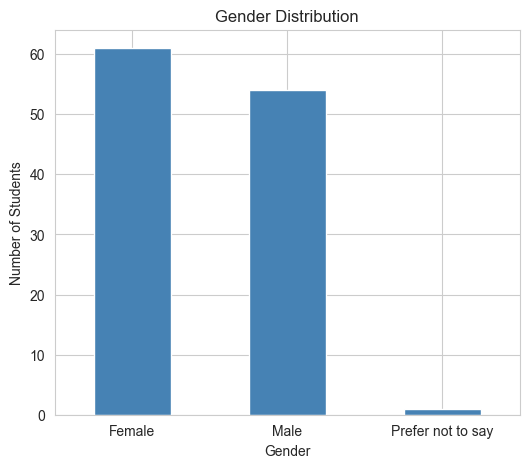

In [10]:
# gender
df["gender"].value_counts().plot(kind="bar", color="steelblue", figsize=(6, 5))
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

**Figure 2: Accommodation Type Distribution**

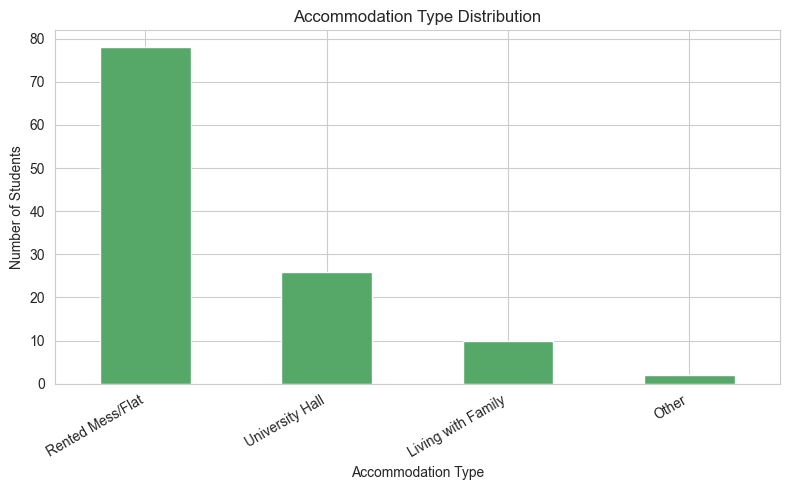

In [11]:
df["accommodation"].value_counts().plot(kind="bar", color="#55A868", figsize=(8, 5))
plt.title("Accommodation Type Distribution")
plt.xlabel("Accommodation Type")
plt.ylabel("Number of Students")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Figure 3: Living Satisfaction Distribution**

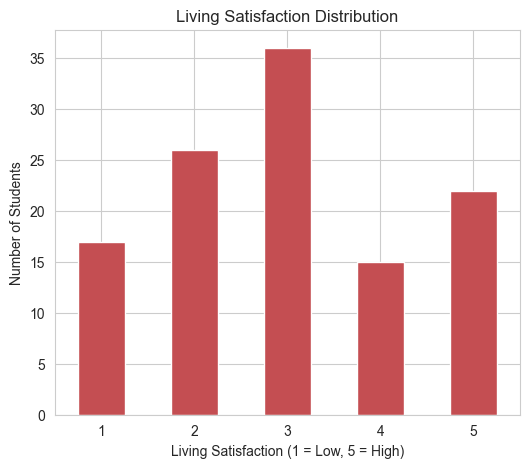

In [12]:
df["living_satisfaction"].value_counts().sort_index().plot(kind="bar", color="#C44E52", figsize=(6, 5))
plt.title("Living Satisfaction Distribution")
plt.xlabel("Living Satisfaction (1 = Low, 5 = High)")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

**Figure 4: CGPA Distribution**

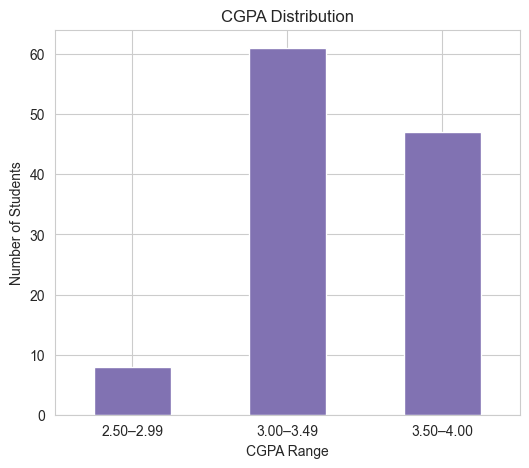

In [13]:
cgpa_order = df["cgpa"].value_counts().sort_index().index
df["cgpa"].value_counts().reindex(cgpa_order).plot(kind="bar", color="#8172B2", figsize=(6, 5))
plt.title("CGPA Distribution")
plt.xlabel("CGPA Range")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

## 6. Encoding categorical columns (Label Encoding)

In [14]:
df_enc = df.copy()
label_encoders = {}

for col in df_enc.columns:
    if df_enc[col].dtype == "object" or str(df_enc[col].dtype) == "str":
        le = LabelEncoder()
        df_enc[col] = le.fit_transform(df_enc[col].astype(str))
        label_encoders[col] = le

print("Encoded columns:", list(label_encoders.keys()))
df_enc.head()

Encoded columns: ['gender', 'age', 'department', 'year', 'accommodation', 'applied_hall', 'hall_status', 'distance', 'commute_oneway', 'commute_total', 'transport', 'transport_cost', 'late_frequency', 'living_cost', 'cgpa', 'study_hours', 'attendance', 'miss_classes', 'study_difficulty', 'grade_decrease', 'sleep_hours', 'isolated', 'academic_pressure', 'study_environment', 'expense_affects_study']


,gender,age,department,year,accommodation,applied_hall,hall_status,roommates,living_satisfaction,distance,...,sleep_hours,isolated,academic_pressure,study_environment,extra_curricular,internet_quality,financial_stress,expense_affects_study,safety,safety_impact
0,0,2,20,2,2,0,0,1,2,1,...,2,0,1,1,2.0,4,2,0,1,4
1,0,2,15,2,2,1,0,2,4,2,...,1,0,1,0,2.0,2,4,1,3,4
2,0,2,16,3,2,0,0,1,2,1,...,1,1,1,0,2.0,3,5,1,3,4
3,0,2,15,2,2,0,0,1,1,1,...,0,0,0,1,1.0,4,3,1,1,5
4,1,2,20,2,3,1,2,5,4,5,...,0,2,1,1,1.0,4,4,0,3,3


## 7. Correlation analysis
**Figure 5: Correlation Heatmap**

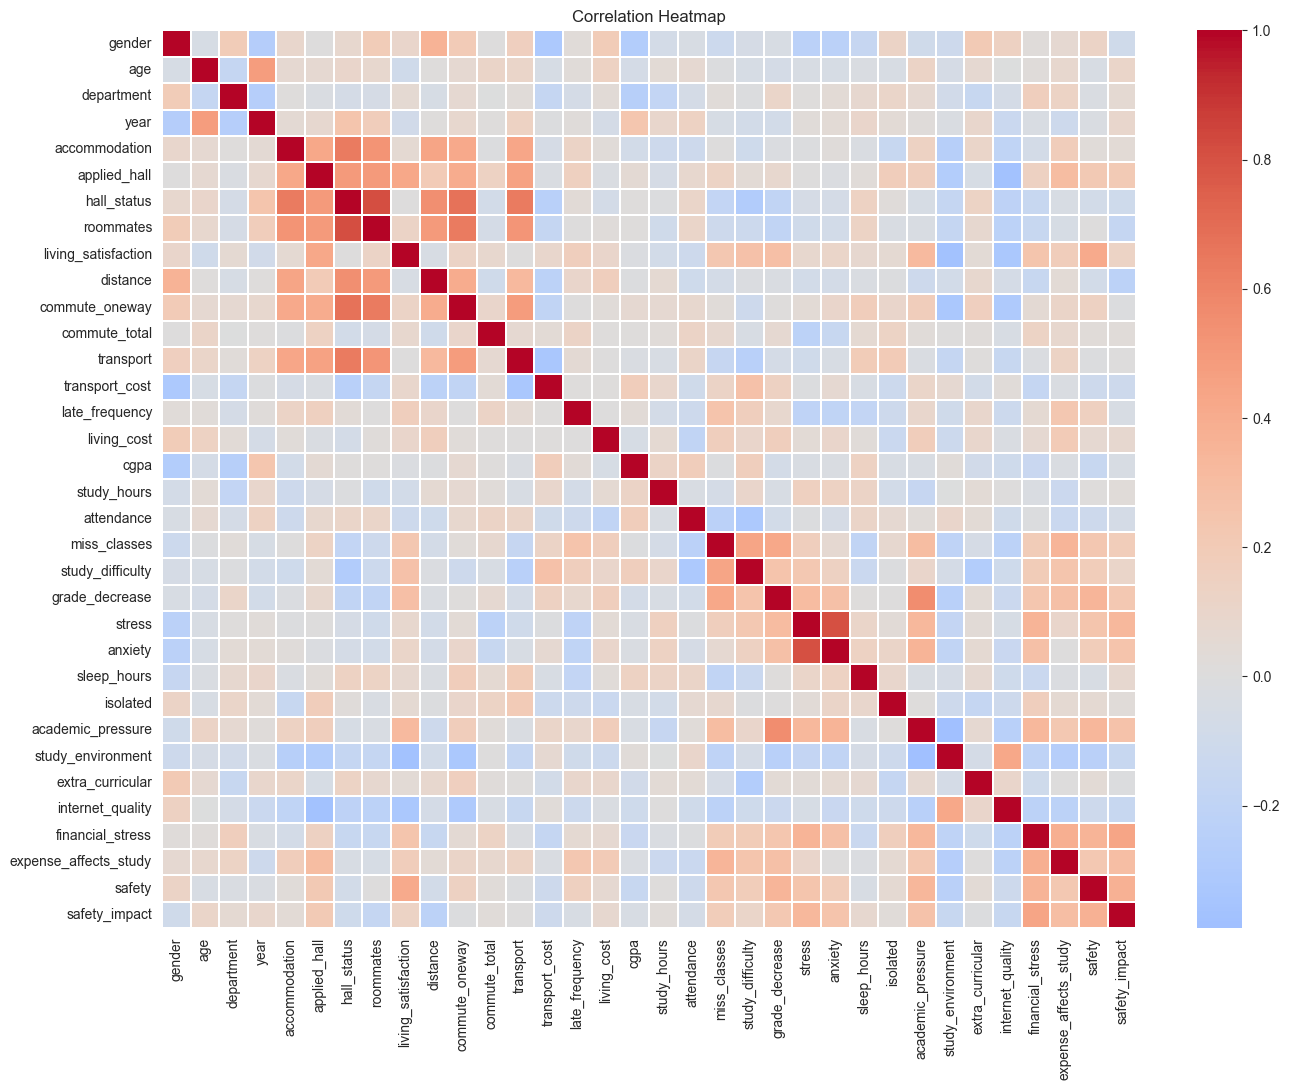

In [15]:
plt.figure(figsize=(14, 11))
sns.heatmap(df_enc.corr(), cmap="coolwarm", center=0, linewidths=0.3)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 8. Model training function
Steps: train-test split (80:20) -> StandardScaler -> SMOTE on training data only -> train 6 models -> evaluate.

In [16]:
def run_models(target, drop_cols=[]):
    X = df_enc.drop(columns=[target] + drop_cols)
    y = df_enc[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y)

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # smote needs k_neighbors smaller than the smallest class
    k = max(1, min(5, y_train.value_counts().min() - 1))
    smote = SMOTE(random_state=42, k_neighbors=k)
    X_train, y_train = smote.fit_resample(X_train, y_train)

    # xgboost needs labels starting from 0
    y_min = y_train.min()

    models = {
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "Random Forest": RandomForestClassifier(random_state=42),
        "XGBoost": XGBClassifier(random_state=42, eval_metric="mlogloss", verbosity=0),
        "Logistic Regression": LogisticRegression(max_iter=1000),
        "Support Vector Machine": SVC(),
        "KNN": KNeighborsClassifier()
    }

    rows = []
    preds = {}
    for name, model in models.items():
        if name == "XGBoost":
            model.fit(X_train, y_train - y_min)
            pred = model.predict(X_test) + y_min
        else:
            model.fit(X_train, y_train)
            pred = model.predict(X_test)

        preds[name] = pred
        rows.append({
            "Model": name,
            "Accuracy (%)": round(accuracy_score(y_test, pred) * 100, 2),
            "Precision": precision_score(y_test, pred, average="weighted", zero_division=0),
            "Recall": recall_score(y_test, pred, average="weighted", zero_division=0),
            "F1 Score": f1_score(y_test, pred, average="weighted", zero_division=0)
        })

    results = pd.DataFrame(rows).sort_values("Accuracy (%)", ascending=False)
    results = results.reset_index(drop=True)
    return results, models, preds, y_test, X.columns

## 9. Experiment 1: CGPA prediction
**Table 5**

In [17]:
cgpa_results, cgpa_models, cgpa_preds, cgpa_ytest, features = run_models("cgpa")
cgpa_results

,Model,Accuracy (%),Precision,Recall,F1 Score
0,Support Vector Machine,62.50,0.643750,0.625000,0.620370
1,Random Forest,45.83,0.446338,0.458333,0.450264
2,Decision Tree,41.67,0.464286,0.416667,0.418860
3,XGBoost,37.50,0.371032,0.375000,0.364087
4,Logistic Regression,29.17,0.315705,0.291667,0.294928
5,KNN,29.17,0.343056,0.291667,0.281944


**Figure 6: Top 10 Feature Importances (Random Forest)**

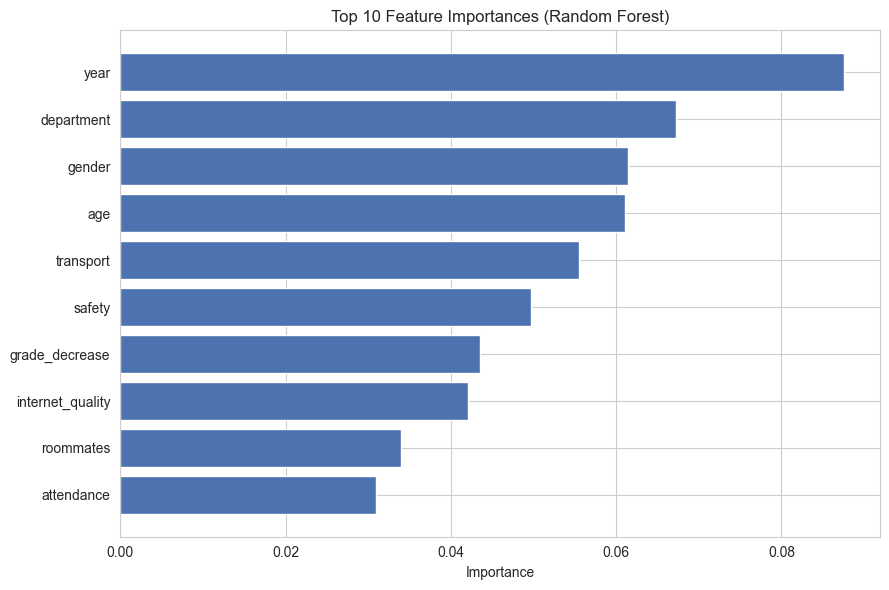

             Feature  Importance
3               year    0.087544
2         department    0.067245
0             gender    0.061434
1                age    0.061031
12         transport    0.055498
31            safety    0.049711
20    grade_decrease    0.043488
28  internet_quality    0.042128
7          roommates    0.033994
17        attendance    0.031005


In [18]:
rf = cgpa_models["Random Forest"]
imp = pd.DataFrame({"Feature": features, "Importance": rf.feature_importances_})
imp = imp.sort_values("Importance", ascending=False).head(10)

plt.figure(figsize=(9, 6))
plt.barh(imp["Feature"], imp["Importance"], color="#4C72B0")
plt.title("Top 10 Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
print(imp)

**Figure 7: Confusion Matrix - Support Vector Machine (CGPA Prediction)**

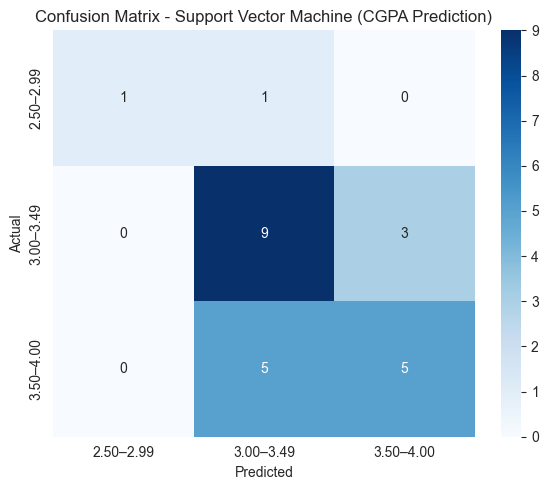

              precision    recall  f1-score   support

   2.50–2.99       1.00      0.50      0.67         2
   3.00–3.49       0.60      0.75      0.67        12
   3.50–4.00       0.62      0.50      0.56        10

    accuracy                           0.62        24
   macro avg       0.74      0.58      0.63        24
weighted avg       0.64      0.62      0.62        24



In [19]:
cgpa_labels = list(label_encoders["cgpa"].classes_)
cm = confusion_matrix(cgpa_ytest, cgpa_preds["Support Vector Machine"])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=cgpa_labels, yticklabels=cgpa_labels)
plt.title("Confusion Matrix - Support Vector Machine (CGPA Prediction)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print(classification_report(cgpa_ytest, cgpa_preds["Support Vector Machine"], target_names=cgpa_labels, zero_division=0))

## 10. Experiment 2: Living satisfaction (5 classes)
**Table 6**

In [20]:
ls5_results, ls5_models, ls5_preds, ls5_ytest, _ = run_models("living_satisfaction")
ls5_results

,Model,Accuracy (%),Precision,Recall,F1 Score
0,Support Vector Machine,41.67,0.491667,0.416667,0.389250
1,Random Forest,37.50,0.397917,0.375000,0.373366
2,Logistic Regression,29.17,0.423032,0.291667,0.321090
3,XGBoost,29.17,0.260119,0.291667,0.262663
4,KNN,20.83,0.152083,0.208333,0.169444
5,Decision Tree,16.67,0.152778,0.166667,0.159091


**Figure 8: Confusion Matrix - Random Forest (Five-Class Living Satisfaction)**

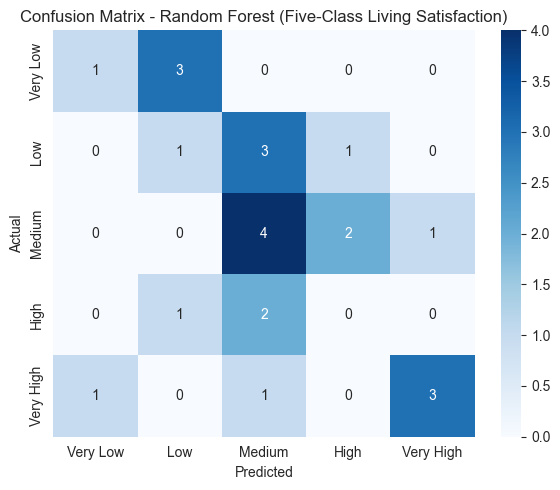

              precision    recall  f1-score   support

    Very Low       0.50      0.25      0.33         4
         Low       0.20      0.20      0.20         5
      Medium       0.40      0.57      0.47         7
        High       0.00      0.00      0.00         3
   Very High       0.75      0.60      0.67         5

    accuracy                           0.38        24
   macro avg       0.37      0.32      0.33        24
weighted avg       0.40      0.38      0.37        24



In [21]:
ls5_labels = ["Very Low", "Low", "Medium", "High", "Very High"]
cm = confusion_matrix(ls5_ytest, ls5_preds["Random Forest"])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ls5_labels, yticklabels=ls5_labels)
plt.title("Confusion Matrix - Random Forest (Five-Class Living Satisfaction)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print(classification_report(ls5_ytest, ls5_preds["Random Forest"], target_names=ls5_labels, zero_division=0))

## 11. Experiment 3: Living satisfaction (3 classes)
The 5 levels are grouped into Low (1-2), Medium (3) and High (4-5) to reduce class imbalance.

**Table 7**

In [22]:
df_enc["living_sat_3"] = df["living_satisfaction"].apply(
    lambda x: 0 if x <= 2 else (1 if x == 3 else 2))

ls3_results, ls3_models, ls3_preds, ls3_ytest, _ = run_models(
    "living_sat_3", drop_cols=["living_satisfaction"])
ls3_results

,Model,Accuracy (%),Precision,Recall,F1 Score
0,KNN,66.67,0.656656,0.666667,0.656838
1,Decision Tree,62.50,0.699679,0.625000,0.634921
2,Support Vector Machine,58.33,0.560426,0.583333,0.567521
3,Random Forest,50.00,0.489815,0.500000,0.490927
4,Logistic Regression,45.83,0.451190,0.458333,0.453509
5,XGBoost,41.67,0.416667,0.416667,0.415724


**Figure 9: Confusion Matrix - K-Nearest Neighbors (Three-Class Living Satisfaction)**

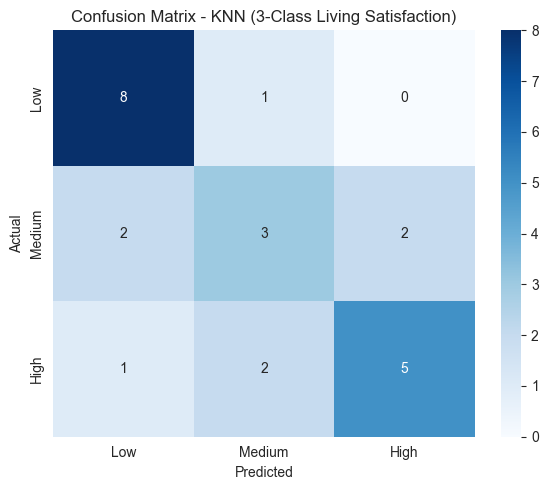

              precision    recall  f1-score   support

         Low       0.73      0.89      0.80         9
      Medium       0.50      0.43      0.46         7
        High       0.71      0.62      0.67         8

    accuracy                           0.67        24
   macro avg       0.65      0.65      0.64        24
weighted avg       0.66      0.67      0.66        24



In [23]:
ls3_labels = ["Low", "Medium", "High"]
cm = confusion_matrix(ls3_ytest, ls3_preds["KNN"])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ls3_labels, yticklabels=ls3_labels)
plt.title("Confusion Matrix - KNN (3-Class Living Satisfaction)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print(classification_report(ls3_ytest, ls3_preds["KNN"], target_names=ls3_labels, zero_division=0))

## 12. Model accuracy comparison
**Figure 10**

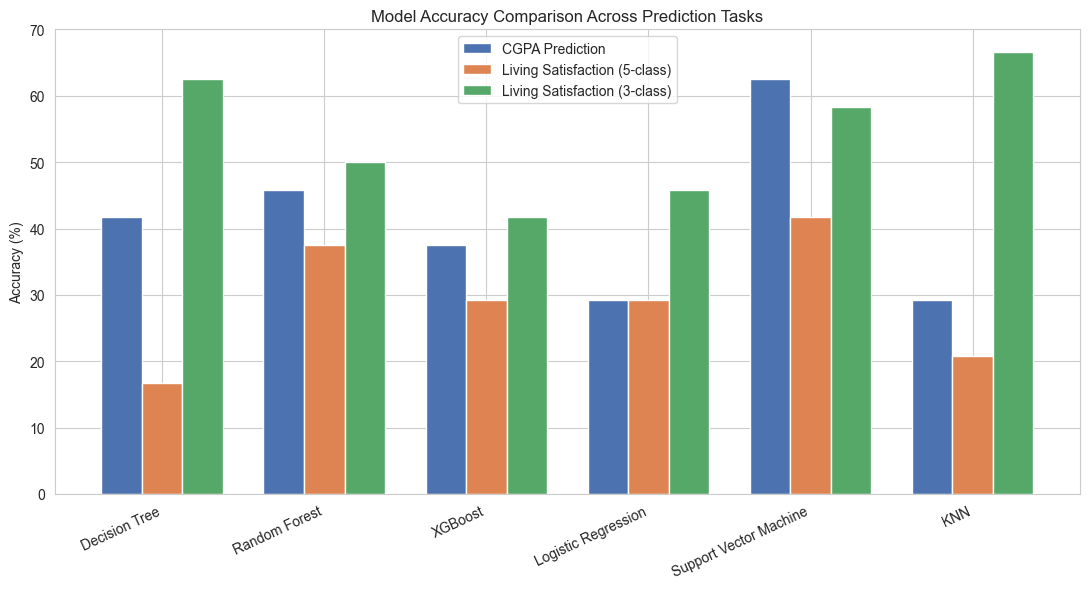

In [24]:
model_names = ["Decision Tree", "Random Forest", "XGBoost",
               "Logistic Regression", "Support Vector Machine", "KNN"]

acc_cgpa = cgpa_results.set_index("Model")["Accuracy (%)"]
acc_ls5 = ls5_results.set_index("Model")["Accuracy (%)"]
acc_ls3 = ls3_results.set_index("Model")["Accuracy (%)"]

x = np.arange(len(model_names))
w = 0.25

plt.figure(figsize=(11, 6))
plt.bar(x - w, [acc_cgpa[m] for m in model_names], w, label="CGPA Prediction", color="#4C72B0")
plt.bar(x, [acc_ls5[m] for m in model_names], w, label="Living Satisfaction (5-class)", color="#DD8452")
plt.bar(x + w, [acc_ls3[m] for m in model_names], w, label="Living Satisfaction (3-class)", color="#55A868")
plt.xticks(x, model_names, rotation=25, ha="right")
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison Across Prediction Tasks")
plt.legend()
plt.tight_layout()
plt.show()

## 13. Saving the best CGPA model

In [25]:
best_name = cgpa_results.loc[0, "Model"]
joblib.dump(cgpa_models[best_name], "best_model_cgpa.pkl")
joblib.dump(label_encoders, "label_encoders.pkl")
print("Best model for CGPA:", best_name, "-", cgpa_results.loc[0, "Accuracy (%)"], "%")

Best model for CGPA: Support Vector Machine - 62.5 %
